In [1]:
%pip install pymongo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 10.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [13]:
import os
import pymongo

# Connect to the 'mongo' service on its default port
client = pymongo.MongoClient(os.getenv("MONGODB_URI", "mongodb://localhost:27017/"))

# Access the database you defined in your Spark job
db = client['air_quality_db'] 
collection = db['aggregated_metrics']

print("Successfully connected to MongoDB.")
print(f"Found {collection.count_documents({})} documents in 'aggregated_metrics'.")
print("-" * 30)
print("Here are the first 5 documents:")

# Find and print the first 5 documents
for doc in collection.find().limit(5):
    print(doc)

client.close()

Successfully connected to MongoDB.
Found 5990 documents in 'aggregated_metrics'.
------------------------------
Here are the first 5 documents:
{'_id': ObjectId('690ec8f9b4088869c7d346ce'), 'window': {'start': datetime.datetime(2025, 11, 8, 4, 33), 'end': datetime.datetime(2025, 11, 8, 4, 43)}, 'city': 'Los Angeles', 'avg_pm25': 35.58684203499242, 'avg_pm10': 61.84789396587171, 'avg_no2': 31.48894721583316, 'avg_so2': 9.771052666400609, 'avg_co': 2.2094736969784687, 'valid_count': 19, 'total_count': 19, 'valid_rate': 1.0}
{'_id': ObjectId('690ec8f9b4088869c7d346d5'), 'window': {'start': datetime.datetime(2025, 11, 8, 4, 35), 'end': datetime.datetime(2025, 11, 8, 4, 45)}, 'city': 'Los Angeles', 'avg_pm25': 35.58684203499242, 'avg_pm10': 61.84789396587171, 'avg_no2': 31.48894721583316, 'avg_so2': 9.771052666400609, 'avg_co': 2.2094736969784687, 'valid_count': 19, 'total_count': 19, 'valid_rate': 1.0}
{'_id': ObjectId('690ec8feb4088869c7d346be'), 'window': {'start': datetime.datetime(2025

In [14]:
import os
import pandas as pd
import pymongo

# Connect to MongoDB and load all data
client = pymongo.MongoClient(os.getenv("MONGODB_URI", "mongodb://localhost:27017/"))
db = client['air_quality_db']
collection = db['aggregated_metrics']
data = list(collection.find())
client.close()

# Convert data to a Pandas DataFrame
df = pd.DataFrame(data)

# --- Data Cleaning ---
# Extract the 'end' time from the 'window' dictionary
df['window_end'] = df['window'].apply(lambda x: x['end'])

# Convert the 'window_end' to a proper datetime object for plotting
df['window_end'] = pd.to_datetime(df['window_end'])

# Sort by time
df = df.sort_values(by='window_end')

print(f"Successfully loaded {len(df)} records into a Pandas DataFrame.")
print("DataFrame Head:")
display(df.head())

Successfully loaded 5990 records into a Pandas DataFrame.
DataFrame Head:


,_id,window,city,avg_pm25,avg_pm10,avg_no2,avg_so2,avg_co,valid_count,total_count,valid_rate,max_pm25,window_end
21,690ec8fab4088869c7d346e2,"{'start': 2025-11-08 04:27:00, 'end': 2025-11-...",New York,29.712001,60.417000,29.642000,12.938000,1.642000,10,10,1.0,NaN,2025-11-08 04:37:00
30,690ec8fbb4088869c7d346f1,"{'start': 2025-11-08 04:27:00, 'end': 2025-11-...",Los Angeles,40.345000,63.408000,29.994000,10.481000,2.276000,10,10,1.0,NaN,2025-11-08 04:37:00
4,690ec8feb4088869c7d346bc,"{'start': 2025-11-08 04:27:00, 'end': 2025-11-...",Chicago,24.595000,44.305000,26.493000,9.591000,2.834000,10,10,1.0,NaN,2025-11-08 04:37:00
26,690ec8fbb4088869c7d346ea,"{'start': 2025-11-08 04:27:00, 'end': 2025-11-...",Phoenix,29.427778,50.924445,30.808888,11.313333,2.122222,9,9,1.0,NaN,2025-11-08 04:37:00
15,690ec8f9b4088869c7d346d1,"{'start': 2025-11-08 04:27:00, 'end': 2025-11-...",Houston,32.733000,68.941000,31.310000,6.806000,2.557000,10,10,1.0,NaN,2025-11-08 04:37:00


Line Chart

Generating PM2.5 trend plot...


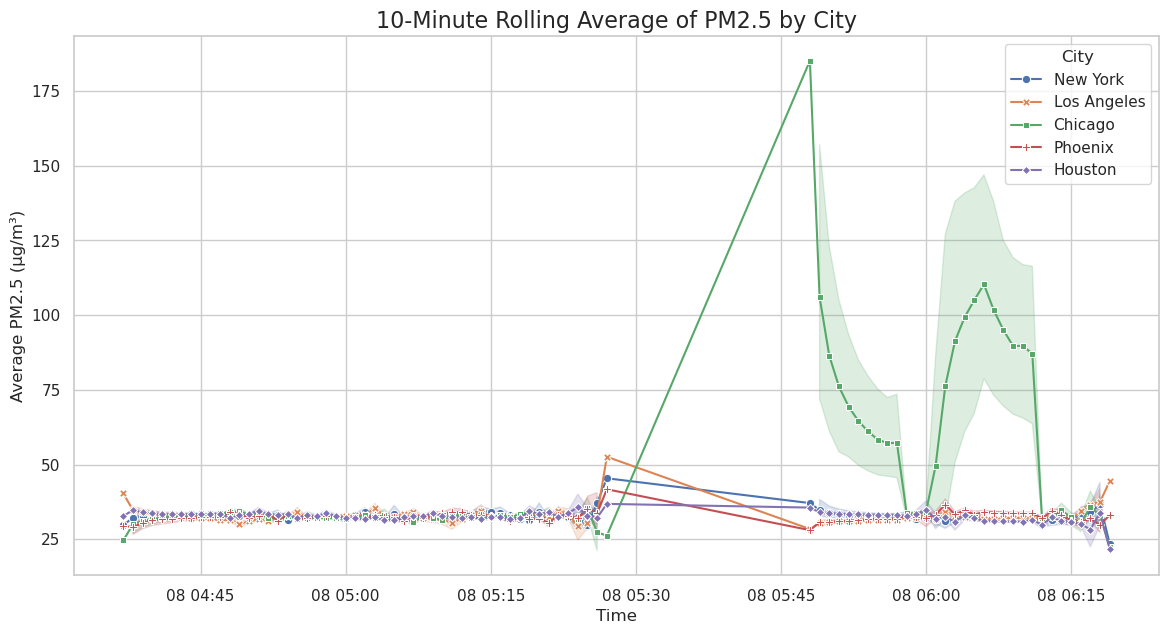

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plot style
sns.set_theme(style="whitegrid")

print("Generating PM2.5 trend plot...")
plt.figure(figsize=(14, 7))

# Plot PM2.5 trends over time, with a separate line (hue) for each city
ax = sns.lineplot(
    data=df,
    x='window_end',
    y='avg_pm25',
    hue='city',
    style='city',
    markers=True,
    dashes=False
)

ax.set_title('10-Minute Rolling Average of PM2.5 by City', fontsize=16)
ax.set_xlabel('Time')
ax.set_ylabel('Average PM2.5 (µg/m³)')
plt.legend(title='City', loc='upper right')
plt.show()

Bar Chart

Generating Top Polluted Cities plot...


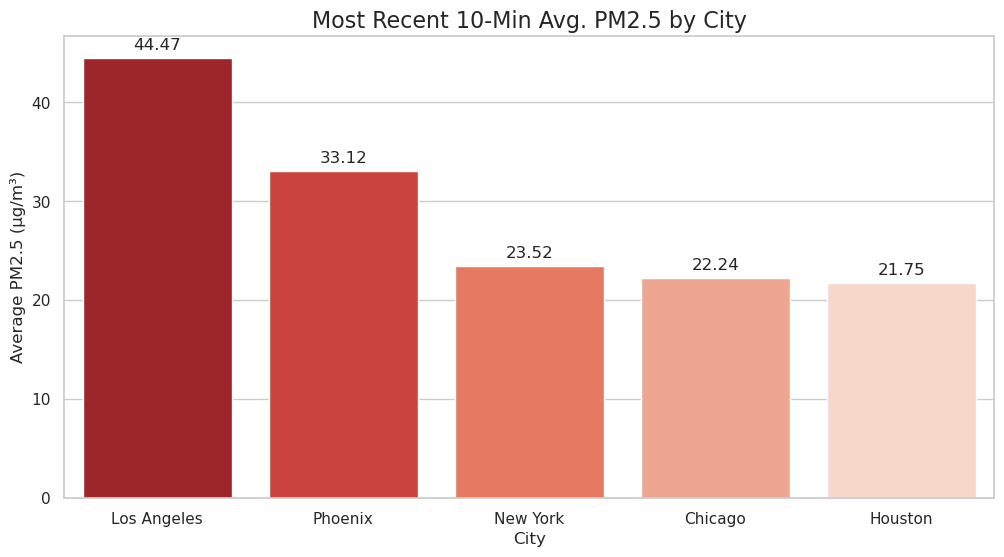

In [16]:
print("Generating Top Polluted Cities plot...")

# (The top part of your code is correct)
if 'df' in locals() and not df.empty:
    latest_df = df.loc[df.groupby('city')['window_end'].idxmax()]
    latest_df = latest_df.sort_values(by='avg_pm25', ascending=False)

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        data=latest_df,
        x='city',
        y='avg_pm25',
        palette='Reds_r',
        hue='city',        
        legend=False       
    )

    ax.set_title('Most Recent 10-Min Avg. PM2.5 by City', fontsize=16)
    ax.set_xlabel('City')
    ax.set_ylabel('Average PM2.5 (µg/m³)')

    # Add value labels on top of the bars
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}",                  # type: ignore
                    (p.get_x() + p.get_width() / 2., p.get_height()), # type: ignore
                    ha='center', va='center', 
                    xytext=(0, 9), 
                    textcoords='offset points')
    
    plt.show()
else:
    print("DataFrame 'df' not found or is empty. Please run the cell that loads data from MongoDB first.")

Alert Log Table

In [17]:
import os
print("Generating Alert Log Table...")

import pymongo, pandas as pd

MONGO_URI = os.getenv("MONGODB_URI", "mongodb://localhost:27017/")
DB_NAME = "air_quality_db"

client = pymongo.MongoClient(MONGO_URI)
alerts = list(client[DB_NAME]["alerts"].find().sort([("_id", -1)]).limit(200))
client.close()

if not alerts:
    print("No alerts have fired yet.")
else:
    alert_df = pd.json_normalize(alerts)

    # derive window_end robustly
    if "window.end" in alert_df.columns:
        alert_df["window_end"] = pd.to_datetime(alert_df["window.end"])
    elif "window_end" in alert_df.columns:
        alert_df["window_end"] = pd.to_datetime(alert_df["window_end"])

    # keep only meaningful columns that exist
    keep_cols = [c for c in ["city","window_end","avg_pm25","avg_pm10","severity","processing_time"] if c in alert_df.columns]
    alert_df = alert_df.sort_values(by="avg_pm25", ascending=False, na_position="last")

    print(f"SUCCESS! Found {len(alert_df)} alert row(s).")
    display(alert_df[keep_cols].head(20))


Generating Alert Log Table...
SUCCESS! Found 7 alert row(s).


,city,window_end,avg_pm25,avg_pm10,severity,processing_time
5,Chicago,2025-11-08 06:01:00,228.599998,327.650002,CRITICAL,2025-11-08 06:03:30.004
6,Chicago,2025-11-08 05:48:00,185.144737,269.324213,CRITICAL,2025-11-08 05:50:32.988
4,Chicago,2025-11-08 06:02:00,154.693750,228.777031,CRITICAL,2025-11-08 06:04:30.006
3,Chicago,2025-11-08 06:03:00,95.192357,147.977642,CRITICAL,2025-11-08 06:05:30.021
2,Chicago,2025-11-08 06:04:00,74.610874,117.473880,CRITICAL,2025-11-08 06:06:30.004
1,Chicago,2025-11-08 06:05:00,64.750041,102.364274,CRITICAL,2025-11-08 06:07:30.025
0,Chicago,2025-11-08 06:06:00,58.720066,91.747641,CRITICAL,2025-11-08 06:08:33.912


KPI Summary

In [18]:
import os
MONGO_URI = os.getenv("MONGODB_URI", "mongodb://localhost:27017/")
DB_NAME   = "air_quality_db"

# --- 0) Ensure aggregated DataFrame `df` exists ---
try:
    df  # will NameError if not defined
except NameError:
    client = pymongo.MongoClient(MONGO_URI)
    data = list(client[DB_NAME]["aggregated_metrics"].find())
    client.close()
    df = pd.json_normalize(data)

# Derive/standardize window_end for `df`
if "window_end" in df.columns:
    df["window_end"] = pd.to_datetime(df["window_end"], errors="coerce")
elif "window.end" in df.columns:
    df["window_end"] = pd.to_datetime(df["window.end"], errors="coerce")
elif "window.end.$date" in df.columns:
    df["window_end"] = pd.to_datetime(df["window.end.$date"], errors="coerce")

# --- 1) Build alerts DataFrame `alert_df` from Mongo (preferred) ---
try:
    client = pymongo.MongoClient(MONGO_URI)
    alerts_raw = list(client[DB_NAME]["alerts"].find().sort([("_id", -1)]).limit(1000))
    client.close()
except Exception:
    alerts_raw = []

if alerts_raw:
    alert_df = pd.json_normalize(alerts_raw)
    if "window_end" in alert_df.columns:
        alert_df["window_end"] = pd.to_datetime(alert_df["window_end"], errors="coerce")
    elif "window.end" in alert_df.columns:
        alert_df["window_end"] = pd.to_datetime(alert_df["window.end"], errors="coerce")
    elif "window.end.$date" in alert_df.columns:
        alert_df["window_end"] = pd.to_datetime(alert_df["window.end.$date"], errors="coerce")
else:
    # Fallback: derive alerts from `df` if severity present
    if "severity" in df.columns:
        alert_df = df[df["severity"].isin(["WARNING", "CRITICAL"])].copy()
        # ensure a window_end column
        if "window_end" not in alert_df.columns:
            if "window.end" in alert_df.columns:
                alert_df["window_end"] = pd.to_datetime(alert_df["window.end"], errors="coerce")
            elif "window.end.$date" in alert_df.columns:
                alert_df["window_end"] = pd.to_datetime(alert_df["window.end.$date"], errors="coerce")
    else:
        alert_df = pd.DataFrame([])

print("="*30)
print("PROJECT KPI SUMMARY")
print("="*30)

# --- 2) KPIs ---
if df.empty:
    print("No data processed yet.")
else:
    # 2.1) Total Alerts
    total_alerts = len(alert_df) if not alert_df.empty else 0
    print(f"Total 10-Minute Alert Windows: {total_alerts}")

    # 2.2) Highest PM2.5 10-min average
    if "avg_pm25" in df.columns:
        avg_pm25_numeric = pd.to_numeric(df["avg_pm25"], errors="coerce")
        highest_pm25 = avg_pm25_numeric.max()
        if pd.notna(highest_pm25):
            city_with_highest = None
            try:
                idx = avg_pm25_numeric.idxmax()
                if "city" in df.columns:
                    city_with_highest = df.loc[idx, "city"]
            except Exception:
                pass
            if city_with_highest:
                print(f"Highest PM2.5 10-Min Avg: {highest_pm25:.2f} (in {city_with_highest})")
            else:
                print(f"Highest PM2.5 10-Min Avg: {highest_pm25:.2f}")
        else:
            print("Highest PM2.5 10-Min Avg: N/A")
    else:
        print("Highest PM2.5 10-Min Avg: N/A (field not present)")

    # 2.2b) Highest 1-min max within any 10-min window (if you added max_pm25 in Spark)
    if "max_pm25" in df.columns:
        max_pm25_numeric = pd.to_numeric(df["max_pm25"], errors="coerce")
        highest_max_pm25  = max_pm25_numeric.max()
        if pd.notna(highest_max_pm25):
            print(f"Highest PM2.5 1-Min Max (within any 10-min window): {highest_max_pm25:.2f}")

    # 2.3) City with Most Alerts
    if total_alerts > 0 and "city" in alert_df.columns:
        most_alerted_city = alert_df["city"].mode()[0]
        alert_count = (alert_df["city"] == most_alerted_city).sum()
        print(f"City with Most Alerts: {most_alerted_city} ({alert_count} alert windows)")
    else:
        print("City with Most Alerts: N/A (no alerts)")

    # 2.4) Total Windows Processed
    print(f"Total 10-Min Windows Read: {len(df)}")

    # 2.5) Data Quality: Average valid_rate
    if "valid_rate" in df.columns:
        vr = pd.to_numeric(df["valid_rate"], errors="coerce")
        if vr.notna().any():
            print(f"Average valid_rate: {vr.mean():.3f}")
        else:
            print("Average valid_rate: N/A")
    else:
        print("Average valid_rate: N/A (field not present)")


PROJECT KPI SUMMARY
Total 10-Minute Alert Windows: 8
Highest PM2.5 10-Min Avg: 228.60 (in Chicago)
Highest PM2.5 1-Min Max (within any 10-min window): 248.95
City with Most Alerts: Chicago (8 alert windows)
Total 10-Min Windows Read: 5990
Average valid_rate: 1.000


In [19]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [20]:
import os
# --- Simple 10-minute series for one city ---
import pandas as pd
import pymongo

TARGET_CITY = "chicago"

# Load df from Mongo only if not already present
try:
    df
except NameError:
    client = pymongo.MongoClient(os.getenv("MONGODB_URI", "mongodb://localhost:27017/"))
    data = list(client["air_quality_db"]["aggregated_metrics"].find())
    client.close()
    df = pd.json_normalize(data)

# Pick the first window-end column that exists
win_col = next((c for c in ["window_end", "window.end", "window.end.$date"] if c in df.columns), None)
if not win_col:
    raise ValueError("No window end column found (looked for window_end / window.end / window.end.$date).")

# Standardize to a datetime 'window_end' column and index
df["window_end"] = pd.to_datetime(df[win_col])
df = df.sort_values("window_end").set_index("window_end")

# Ensure metric is numeric
df["avg_pm25"] = pd.to_numeric(df.get("avg_pm25", pd.Series(dtype=float)), errors="coerce")

# Filter the city (case-insensitive; skip if 'city' not present)
if "city" in df.columns:
    s = df["city"].astype(str).str.lower()
    df_city = df[s == TARGET_CITY].copy()
else:
    df_city = df.copy()

# Resample to strict 10-minute bins and fill gaps
df_city_resampled = (
    df_city[["avg_pm25"]]
      .resample("10T").mean()
      .asfreq("10T")
      .ffill().bfill()
)

print(f"{TARGET_CITY.title()} rows: {len(df_city)}  |  10-min points: {len(df_city_resampled)}")
display(df_city_resampled.head())


Chicago rows: 1198  |  10-min points: 11


,avg_pm25
window_end,
2025-11-08 04:30:00,30.051921
2025-11-08 04:40:00,33.243376
2025-11-08 04:50:00,32.354487
2025-11-08 05:00:00,32.134267
2025-11-08 05:10:00,32.631030


Training ARIMA(1,1,1) model...
                               SARIMAX Results                                
Dep. Variable:               avg_pm25   No. Observations:                   11
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -48.525
Date:                Sat, 08 Nov 2025   AIC                            103.050
Time:                        06:09:52   BIC                            103.958
Sample:                    11-08-2025   HQIC                           102.054
                         - 11-08-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4816      1.522     -0.316      0.752      -3.465       2.502
ma.L1         -0.2001      2.007     -0.100      0.921      -4.134       3.734
sigma2       914.4922

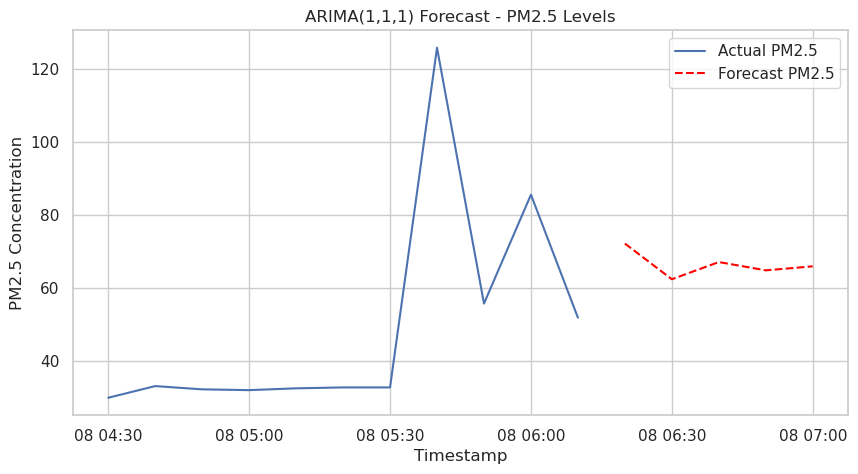

In [21]:
# === Train ARIMA(1,1,1) Model for PM2.5 Forecasting ===
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA  # ensure import
import matplotlib.pyplot as plt

if 'df_city_resampled' in locals() and not df_city_resampled.empty:
    print("Training ARIMA(1,1,1) model...")

    # Define and fit the model (basic order = (1,1,1))
    model = ARIMA(df_city_resampled['avg_pm25'], order=(1, 1, 1))
    model_fit = model.fit()

    # Print model summary
    print(model_fit.summary())

    # --- Forecast Next 5 Intervals (50 mins ahead if using 10T) ---
    forecast_steps = 5
    forecast = model_fit.forecast(steps=forecast_steps)

    # Plot results
    plt.figure(figsize=(10, 5))
    plt.plot(df_city_resampled.index, df_city_resampled['avg_pm25'], label="Actual PM2.5")
    plt.plot(
        pd.date_range(df_city_resampled.index[-1], periods=forecast_steps + 1, freq='10T')[1:],
        forecast,
        label="Forecast PM2.5",
        linestyle="--",
        color="red"
    )
    plt.title("ARIMA(1,1,1) Forecast - PM2.5 Levels")
    plt.xlabel("Timestamp")
    plt.ylabel("PM2.5 Concentration")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Error: No resampled data available to train the ARIMA model.")


Training ARIMA(1,1,1) model...

Model trained successfully. Forecasting next 30 minutes (3 time steps)...


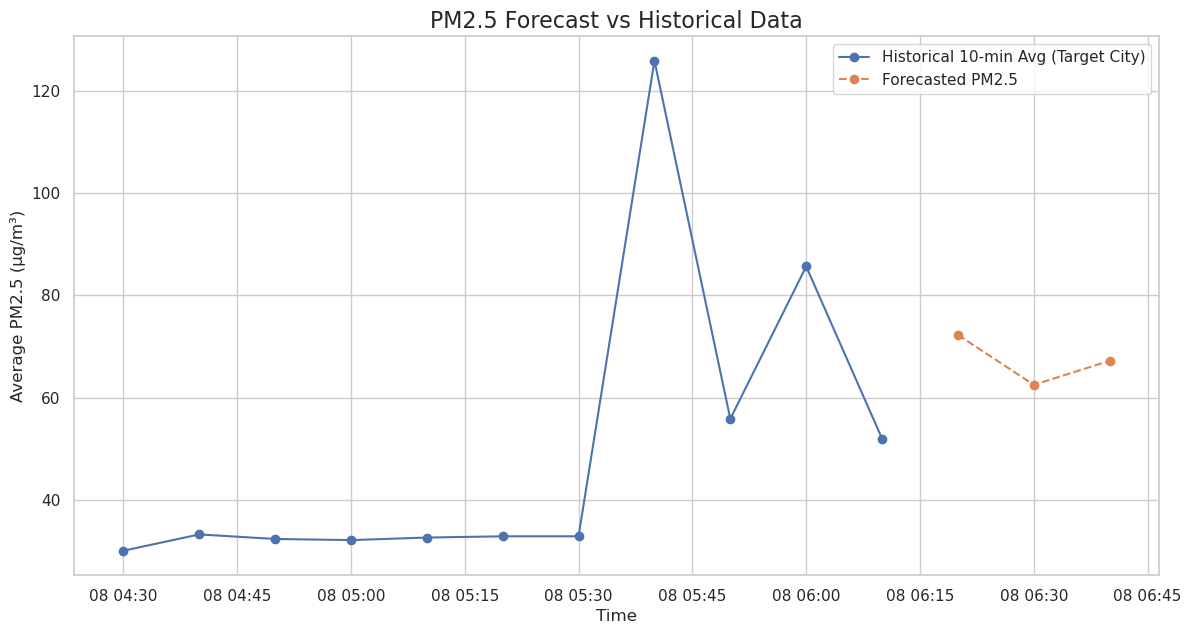

In [22]:
# === Forecast Next 30 Minutes (3 steps) ===
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA  # ensure ARIMA is imported

if 'df_city_resampled' in locals() and not df_city_resampled.empty:
    print("Training ARIMA(1,1,1) model...")

    # Define and fit the ARIMA model
    model = ARIMA(df_city_resampled['avg_pm25'], order=(1,1,1))
    model_fit = model.fit()

    print("\nModel trained successfully. Forecasting next 30 minutes (3 time steps)...")

    # Forecast 3 future time steps (i.e. 30 minutes)
    forecast = model_fit.forecast(steps=3)

    # Plot results
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="whitegrid")

    # Plot historical PM2.5 averages
    plt.plot(df_city_resampled.index, df_city_resampled['avg_pm25'],
             label='Historical 10-min Avg (Target City)', marker='o')

    # Plot forecasted PM2.5 values
    plt.plot(forecast.index, forecast,
             label='Forecasted PM2.5', marker='o', linestyle='--')

    plt.title('PM2.5 Forecast vs Historical Data', fontsize=16)
    plt.xlabel('Time')
    plt.ylabel('Average PM2.5 (µg/m³)')
    plt.legend()
    plt.show()

else:
    print("No resampled data available to train or forecast.")
